# Mission 6 — Waypoint navigation #3: data analytics

The re-test after mission 5's changes (the BNO08x's gyro dynamic calibration turned off, the
rudder centre at 1560 µs). Loads the mission's data from `../data` into pandas and finds when the
autopilot drove the boat towards each of the three destinations.

- `../data/mqtt_20261025_pm.jsonl` — everything on the boat's MQTT topics in the afternoon session,
  as written by the MQTT logger (software/mqtt_logger): telemetry once a second and the commands
  sent to it.
- `../data/mqtt_20261025_pm_runs_1-3.jsonl` — the part analysed here: the session's last three
  destinations, which are mission 4's destinations 1 to 3 in the same order. The session's first
  run is left out.

Times are UTC.
Positions are not displayed; where they are needed they are compared as distances in metres.

In [1]:
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
MEDIA_DIR = Path("../media")
DATASET = DATA_DIR / "mqtt_20261025_pm_runs_1-3.jsonl"

EARTH_RADIUS_M = 6371000


def utc(unix):
    """Unix seconds -> pandas UTC timestamp."""
    return pd.to_datetime(unix, unit="s", utc=True)


def hms(ts):
    return "" if pd.isna(ts) else ts.strftime("%H:%M:%S")

## MQTT log

`tel` is the boat's telemetry flattened into columns (`gps.lat_e7`, `nav.state`,
`compass.virtual.heading`, ...), and `commands` the commands sent to it. `bcu.*` is empty in the
seconds when the Body Control Unit's status read failed its checksum, so `autonomous` carries the
last known switch position forward.

In [2]:
messages = pd.DataFrame([json.loads(line) for line in open(DATASET)])
messages["time"] = utc(messages.unix)

tel = pd.json_normalize([dict(unix=m.unix, **m.data) for m in messages.itertuples() if m.topic.endswith("/telemetry")])
tel["time"] = utc(tel.unix)
tel["autonomous"] = tel["bcu.esp32_mode"].astype("boolean").ffill()
tel["lat"] = tel["gps.lat_e7"] / 1e7
tel["lon"] = tel["gps.lon_e7"] / 1e7

commands = pd.json_normalize([dict(unix=m.unix, **m.data) for m in messages.itertuples() if m.topic.endswith("/cmd")])
commands["time"] = utc(commands.unix)

print("%s: %d messages: %d telemetry, %d commands, from %s to %s UTC" % (
    DATASET.name, len(messages), len(tel), len(commands), hms(messages.time.min()), hms(messages.time.max())))
print("telemetry sequence numbers: %d to %d, %d missing" % (
    tel.seq.min(), tel.seq.max(), tel.seq.max() - tel.seq.min() + 1 - tel.seq.nunique()))
commands[["time", "cmd"]].assign(time=commands.time.map(hms))

mqtt_20261025_pm_runs_1-3.jsonl: 226 messages: 223 telemetry, 3 commands, from 22:11:17 to 22:15:00 UTC
telemetry sequence numbers: 638 to 860, 0 missing


,time,cmd
0,22:11:17,destination
1,22:12:25,destination
2,22:13:31,destination


## The three autopilot runs

For each destination sent:

| Column | What it is |
|---|---|
| sent | When the command was published |
| started | First telemetry message where the boat had the destination and was navigating towards it |
| arrived | First time the boat reported being inside its arrival radius |
| ended | The first of: arrival, the next destination, or the RC switch going off autonomous |

The Body Control Unit only drives the motor while the switch is on autonomous, so *autonomous at
start* says whether that run actually moved the boat.

In [3]:
runs = []
cmd_dest = commands[commands.cmd == "destination"].reset_index(drop=True)
for i, c in cmd_dest.iterrows():
    next_sent = cmd_dest.unix.iloc[i + 1] if i + 1 < len(cmd_dest) else np.inf
    mine = tel[(tel.unix >= c.unix) & (tel.unix < next_sent)
               & (tel["destination.lat_e7"] == c.lat_e7) & (tel["destination.lon_e7"] == c.lon_e7)]
    nav = mine[mine["output.reason"] == "navigating"]
    started = nav.unix.iloc[0] if len(nav) else np.nan
    after = mine[mine.unix >= started] if len(nav) else mine.iloc[0:0]
    arrived = after.loc[after["nav.state"] == "arrived", "unix"].min()
    to_rc = after.loc[after.autonomous == False, "unix"].min()  # noqa: E712 (pandas boolean with NA)
    ends = {"arrived": arrived, "next destination": next_sent, "switched to RC": to_rc}
    ended_by = min((v, k) for k, v in ends.items() if pd.notna(v) and v < np.inf)[1] if len(nav) else ""
    ended = ends.get(ended_by, np.nan)
    first = after.iloc[0] if len(after) else None
    at_arrival = after[after.unix == arrived]
    runs.append({
        "destination": i + 1,
        "sent": utc(c.unix),
        "started": utc(started),
        "arrived": utc(arrived),
        "ended": utc(ended),
        "ended by": ended_by,
        "duration (s)": round(ended - started) if pd.notna(started) and pd.notna(ended) else np.nan,
        "autonomous at start": None if first is None else bool(first.autonomous),
        "distance at start (m)": None if first is None else first["nav.distance_m"],
        "distance at arrival (m)": at_arrival["nav.distance_m"].iloc[0] if len(at_arrival) else np.nan,
        "_start_unix": started, "_end_unix": ended, "_lat_e7": c.lat_e7, "_lon_e7": c.lon_e7,
    })
runs = pd.DataFrame(runs).set_index("destination")

shown = runs.drop(columns=[c for c in runs.columns if c.startswith("_")]).copy()
for col in ("sent", "started", "arrived", "ended"):
    shown[col] = shown[col].map(hms)
shown

,sent,started,arrived,ended,ended by,duration (s),autonomous at start,distance at start (m),distance at arrival (m)
destination,,,,,,,,,
1,22:11:17,22:11:20,22:12:21,22:12:21,arrived,61,True,51.5,3.5
2,22:12:25,22:12:28,22:13:24,22:13:24,arrived,56,True,43.3,3.2
3,22:13:31,22:13:33,22:15:00,22:15:00,arrived,87,True,67.1,3.6


In [4]:
# Telemetry of each run, for the analysis that follows: run_tel[1], run_tel[2], run_tel[3].
run_tel = {n: tel[(tel.unix >= r._start_unix) & (tel.unix <= r._end_unix)] for n, r in runs.iterrows()}
for n in runs.index:
    print("run %d: %d telemetry messages, %d with a valid fix" % (n, len(run_tel[n]), int(run_tel[n]["gps.fix_valid"].astype(bool).sum())))

run 1: 62 telemetry messages, 62 with a valid fix
run 2: 57 telemetry messages, 57 with a valid fix
run 3: 88 telemetry messages, 88 with a valid fix


## Tracks during the autonomous runs

The boat's own GNSS (as it reported it in telemetry), for the three runs only.
Each destination is drawn with its arrival radius. There was no phone reference track.

The axes are metres east and north of the boat's first fix in run 1, which keeps
the coordinates out of the notebook. Set `SHOW_COORDINATES = True` to plot in degrees instead.
The chart is also saved as `../media/tracks.png`.

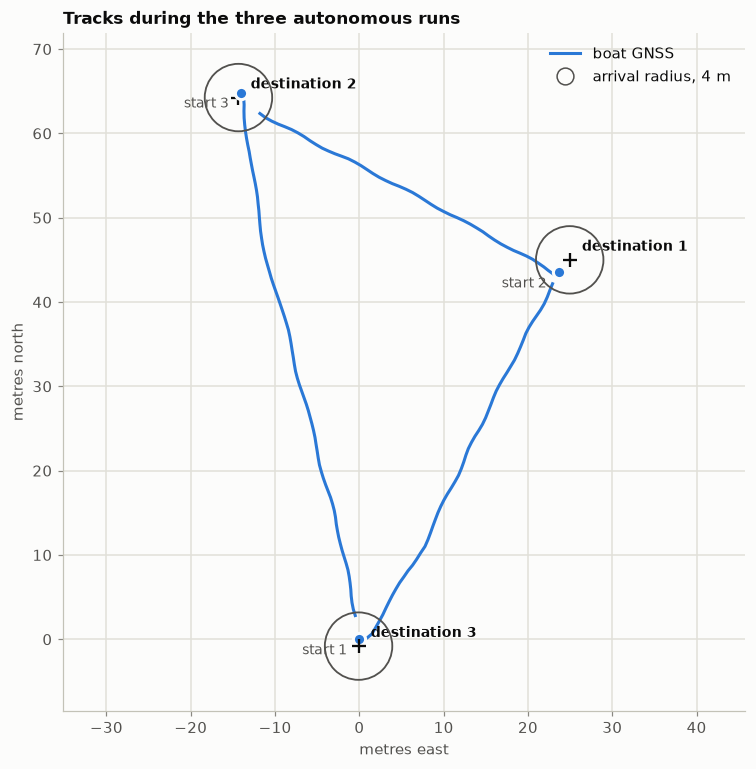

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

SHOW_COORDINATES = False
ARRIVAL_RADIUS_M = 4  # the boat's gnc.py

BOAT = "#2a78d6"  # categorical slot 1, as in mission 4
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

origin = run_tel[runs.index[0]].query("`gps.fix_valid`").iloc[0]


def xy(lat, lon):
    """Plot coordinates: degrees, or metres east / north of the origin (equirectangular)."""
    lat, lon = np.asarray(lat, dtype=float), np.asarray(lon, dtype=float)
    if SHOW_COORDINATES:
        return lon, lat
    east = np.radians(lon - origin.lon) * np.cos(np.radians(origin.lat)) * EARTH_RADIUS_M
    north = np.radians(lat - origin.lat) * EARTH_RADIUS_M
    return east, north


fig, ax = plt.subplots(figsize=(8, 8))
for n, run in runs.iterrows():
    boat = run_tel[n].query("`gps.fix_valid`")
    ax.plot(*xy(boat.lat, boat.lon), color=BOAT, lw=2, label="boat GNSS" if n == runs.index[0] else None)
    sx, sy = xy([boat.lat.iloc[0]], [boat.lon.iloc[0]])
    ax.plot(sx, sy, "o", color=BOAT, ms=8, mec=SURFACE, mew=2, zorder=5)
    ax.annotate("start %d" % n, (sx[0], sy[0]), xytext=(-8, -3), textcoords="offset points", ha="right", va="top", color=INK_2, fontsize=9)

    dx, dy = xy([run._lat_e7 / 1e7], [run._lon_e7 / 1e7])
    if SHOW_COORDINATES:  # the radius in degrees, roughly
        rx = ARRIVAL_RADIUS_M / (EARTH_RADIUS_M * math.cos(math.radians(run._lat_e7 / 1e7))) * 180 / math.pi
    else:
        rx = ARRIVAL_RADIUS_M
    ax.add_patch(Circle((dx[0], dy[0]), rx, fill=False, color=INK_2, lw=1.2, zorder=4))
    ax.plot(dx, dy, "+", color=INK, ms=9, mew=1.5, zorder=5)
    ax.annotate("destination %d" % n, (dx[0], dy[0]), xytext=(8, 6), textcoords="offset points", color=INK, fontsize=9, fontweight="bold")

ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("longitude (°)" if SHOW_COORDINATES else "metres east")
ax.set_ylabel("latitude (°)" if SHOW_COORDINATES else "metres north")
ax.set_title("Tracks during the three autonomous runs")
handles, labels = ax.get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=INK_2, lw=1.2, marker="o", ms=11, mfc="none", ls="none"))
labels.append("arrival radius, %d m" % ARRIVAL_RADIUS_M)
ax.legend(handles, labels, loc="best")
fig.savefig(MEDIA_DIR / "tracks.png", dpi=110, bbox_inches="tight")
plt.show()

## How straight, and the gyro

**Straightness:** how far each track strayed from the straight line between where the run
started and its destination, and how much longer the path was than that line (as in mission 5's
comparison with mission 4).

**The gyro:** under way on the autopilot, how far the gyro yaw turned against the course from
GPS positions and the magnetic heading. In mission 5, with the BNO08x's gyro dynamic calibration
on, the gyro ran about 1°/s ahead of both.

In [6]:
def wrap180(a):
    return (np.asarray(a, dtype=float) + 180) % 360 - 180


rows = {}
for n, run in runs.iterrows():
    boat = run_tel[n].query("`gps.fix_valid`")
    lat0, lon0 = boat.lat.iloc[0], boat.lon.iloc[0]
    to_m = lambda lat, lon: (np.radians(np.asarray(lon) - lon0) * np.cos(np.radians(lat0)) * EARTH_RADIUS_M,
                             np.radians(np.asarray(lat) - lat0) * EARTH_RADIUS_M)
    x, y = to_m(boat.lat, boat.lon)
    dx, dy = to_m(run._lat_e7 / 1e7, run._lon_e7 / 1e7)
    line = math.hypot(dx, dy)
    off = np.abs(x * dy - y * dx) / line
    path = np.sum(np.hypot(np.diff(x), np.diff(y)))
    rows[n] = {"line (m)": round(line), "max off the line (m)": round(float(off.max()), 1),
               "mean off the line (m)": round(float(off.mean()), 1),
               "path longer than the line": "%.1f %%" % (100 * (path / math.hypot(x[-1], y[-1]) - 1))}
display(pd.DataFrame(rows).T.rename_axis("destination"))

BASELINE_S, MIN_SPEED_M_S = 4, 0.5  # as in mission 5
fix = tel["gps.fix_valid"].astype(bool).to_numpy()
t = tel.unix.to_numpy()
la0, lo0 = np.interp(t - BASELINE_S / 2, t[fix], tel.lat[fix]), np.interp(t - BASELINE_S / 2, t[fix], tel.lon[fix])
la1, lo1 = np.interp(t + BASELINE_S / 2, t[fix], tel.lat[fix]), np.interp(t + BASELINE_S / 2, t[fix], tel.lon[fix])
east = np.radians(lo1 - lo0) * np.cos(np.radians(la0)) * EARTH_RADIUS_M
north = np.radians(la1 - la0) * EARTH_RADIUS_M
course, speed = np.degrees(np.arctan2(east, north)) % 360, np.hypot(east, north) / BASELINE_S
under_way = ((tel["nav.state"] == "navigating").to_numpy() & tel.autonomous.fillna(False).to_numpy(bool) & (speed > MIN_SPEED_M_S))[1:]
seconds = np.diff(t)[under_way].sum()
turned = {name: wrap180(np.diff(values))[under_way].sum() for name, values in
          (("GPS course", course), ("magnetic", tel["compass.heading"].to_numpy()), ("gyro", tel["compass.gyro_yaw"].to_numpy()))}
virtual_error = wrap180(tel["compass.virtual.heading"].to_numpy() - course)[1:][under_way]
print("under way on the autopilot, %.0f s: turned %s" % (seconds, ", ".join("%s %+.0f°" % kv for kv in turned.items())))
print("gyro − course %+.2f°/s, gyro − magnetic %+.2f°/s; virtual compass − course: median %+.1f°" % (
    (turned["gyro"] - turned["GPS course"]) / seconds, (turned["gyro"] - turned["magnetic"]) / seconds, np.median(virtual_error)))

,line (m),max off the line (m),mean off the line (m),path longer than the line
destination,,,,
1,51,1.5,0.6,1.4 %
2,43,0.6,0.2,2.5 %
3,67,1.3,0.5,1.4 %


under way on the autopilot, 181 s: turned GPS course -16°, magnetic -9°, gyro -7°
gyro − course +0.05°/s, gyro − magnetic +0.01°/s; virtual compass − course: median -0.1°
